In [1]:
from muon import atac as ac
import pandas as pd
import numpy as np
import pickle
import anndata as ad
import scanpy as sc

/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/py

In [2]:
he_id = 'CTRL04_2010S1121_75_HE'

In [ ]:
atac = sc.read_h5ad(f'../{he_id}_snapATAC_prediction_2x_2000bp_5percent_iStar2xshrink_allcells_50.h5ad')
atac_peak_matrix = np.maximum(0, atac.X)
atac.X = atac_peak_matrix
atac.layers["counts"] = atac.X.copy()

ac.pp.tfidf(atac, scale_factor=1e4)
sc.pp.normalize_per_cell(atac, counts_per_cell_after=1e4)
sc.pp.log1p(atac)

atac.raw = atac

ac.tl.lsi(atac)

atac.obsm['X_lsi'] = atac.obsm['X_lsi'][:,1:]
atac.varm["LSI"] = atac.varm["LSI"][:,1:]
atac.uns["lsi"]["stdev"] = atac.uns["lsi"]["stdev"][1:]

sc.pp.neighbors(atac, use_rep="X_lsi", n_neighbors=25, n_pcs=30, random_state=0)
sc.tl.umap(atac, random_state=0)

sc.tl.leiden(atac, resolution = 0.8, key_added = "leiden_0.8", random_state=0, flavor='igraph', n_iterations=2)
sc.tl.leiden(atac, resolution = 1.0, key_added = "leiden_1.0", random_state=0, flavor='igraph', n_iterations=2)

In [ ]:
sample_id = he_id
atac.uns = {}
atac.uns['spatial'] = {}
atac.uns['spatial'][sample_id] = {}
atac.uns['spatial'][sample_id]['images'] = {}
#adata_query.uns['spatial'][sample_id]['images']['lowres'] = imageLN_flip # rotated_imageLN
atac.uns['spatial'][sample_id]['scalefactors'] = {}
atac.uns['spatial'][sample_id]['scalefactors']['tissue_hires_scalef'] = 16.0  # 78.5
atac.uns['spatial'][sample_id]['scalefactors']['spot_diameter_fullres'] =  20.0 #2.18
atac.uns['spatial'][sample_id]['scalefactors']['fiducial_diameter_fullres'] = 4.24
atac.uns['spatial'][sample_id]['scalefactors']['tissue_lowres_scalef'] = 16.0 # 78.5

atac.obsm['spatial'] = np.array([atac.obs['x'], atac.obs['y']]).T
atac.obs['sample_id'] = [he_id] * atac.n_obs

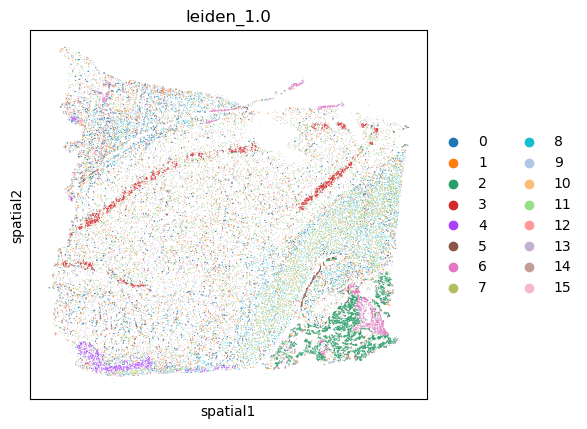

In [21]:
sc.pl.spatial(atac, img_key=None, color='leiden_1.0', size=3.0)

In [22]:
celltype_final = atac.obs['leiden_1.0'].copy().astype(str)
celltype_final[atac.obs['leiden_1.0']=='0'] = 'Microglia'
celltype_final[atac.obs['leiden_1.0']=='1'] = 'Astro'
celltype_final[atac.obs['leiden_1.0']=='2'] = 'Choroid'
celltype_final[atac.obs['leiden_1.0']=='3'] = 'GC_Neuron'
celltype_final[atac.obs['leiden_1.0']=='4'] = 'Unknown'
celltype_final[atac.obs['leiden_1.0']=='5'] = 'LM_glia'
celltype_final[atac.obs['leiden_1.0']=='6'] = 'Vascular'
celltype_final[atac.obs['leiden_1.0']=='7'] = 'Oligo'
celltype_final[atac.obs['leiden_1.0']=='8'] = 'Oligo'
celltype_final[atac.obs['leiden_1.0']=='9'] = 'Astro'
celltype_final[atac.obs['leiden_1.0']=='10'] = 'GC_Neuron'
celltype_final[atac.obs['leiden_1.0']=='11'] = 'CA_Neuron'
celltype_final[atac.obs['leiden_1.0']=='12'] = 'Vascular'
celltype_final[atac.obs['leiden_1.0']=='13'] = 'Oligo'
celltype_final[atac.obs['leiden_1.0']=='14'] = 'Neuron_Other'
celltype_final[atac.obs['leiden_1.0']=='15'] = 'Microglia'
atac.obs['celltype_final'] = celltype_final

In [23]:
atac.uns['celltype_final_colors'] = ['#ffff00', #Astro
 '#FFA500', # CA
 '#bcbd22', # Choroid
 '#d62728', # GC                                         
 '#17becf', # LM
 '#e377c2', # Micro
 '#9467bd', # neurons   
 '#add8e6', # Oligo
 '#7f7f7f', # Unknown
 '#7fff00'] # Vasuclar

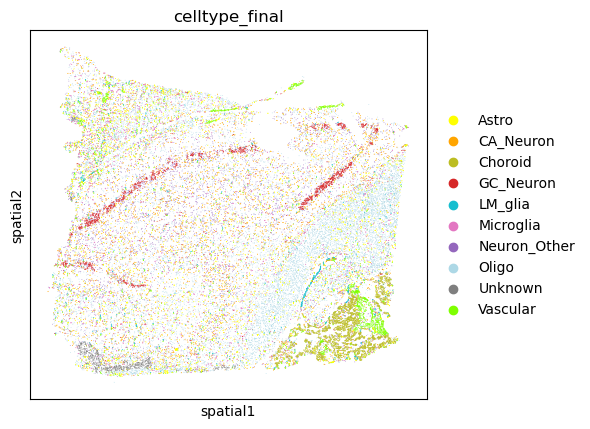

In [24]:
sc.pl.spatial(atac, img_key=None, color='celltype_final', size=3.0)

### Combine >= 5% and 4-5% peaks

In [18]:
atac1 = sc.read_h5ad(f'../{he_id}_snapATAC_prediction_2000bp_4_5percent_iStar2xshrink2_allcells_50.h5ad')
atac_peak_matrix1 = np.maximum(0, atac1.X)
atac1.layers["counts"] = atac1.X.copy()

atac2 = sc.read_h5ad(f'../{he_id}_snapATAC_prediction_2000bp_5percent_iStar2xshrink_allcells_50.h5ad')
atac_peak_matrix2 = np.maximum(0, atac2.X)
atac2.layers["counts"] = atac2.X.copy()

In [30]:
atac_full = sc.concat([atac1, atac2], axis=1, join='outer')

atac_full

/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/anndata/_core/merge.py:1434: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


AnnData object with n_obs × n_vars = 49372 × 32802
    layers: 'counts'

In [25]:
np.sum(atac.obs_names == atac.obs_names)

49372

In [32]:
# Copy obsm (Multidimensional observations/embeddings like LSI, UMAP)
atac_full.obsm = atac.obsm.copy()

# Copy distances/connectivities (usually stored in obsp)
# In scanpy/muon, neighbors results are stored in .obsp
atac_full.obsp = atac.obsp.copy()

# Copy obs (Metadata) excluding 'celltype_final2'
# We use drop to remove the specific column if it exists
atac_full.obs = atac.obs.drop(columns=['celltype_final2'], errors='ignore').copy()

# Optional: Copy uns (Unstructured data like colors and neighbor params)
atac_full.uns = atac.uns.copy()

atac_full

AnnData object with n_obs × n_vars = 49372 × 32802
    obs: 'x', 'y', 'section_id', 'n_counts', 'leiden_0.6', 'leiden_0.8', 'leiden_1.0', 'leiden_1.2', 'sample_id', 'celltype_final'
    uns: 'celltype_final2_colors', 'celltype_final_colors', 'leiden_0.6_colors', 'leiden_0.8_colors', 'leiden_1.0_colors', 'leiden_1.2_colors', 'spatial'
    obsm: 'X_lsi', 'X_umap', 'spatial'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [33]:
atac_full.write_h5ad(f'../{he_id}_snapATAC_prediction_fullpeaks_allcells_annotated.h5ad')